# 07: Baseline model

**DATA 5500, Senior Design**
**Sara Choque Molina**

This notebook is the first answer to Question 1: can a model tell `targeted_threat`, `nontargeted_threat` and `unrelated` articles apart?

This is a first demo. We want three things from it:

1. A look at the labeled data the model learns from (the EDA the instructor asked for).
2. A simple keyword search to compare against. If a model cannot beat a few `if` rules, it is not worth it.
3. A first model, TF-IDF with logistic regression, checked with 5-fold cross-validation.

Before running anything we decided what "worth it" means. The model has to pass all three:

| Criterion | Why |
|---|---|
| Beats the keyword search on kappa | Otherwise the simple rule is enough |
| Cohen kappa against our labels of at least 0.40 | 0.40 is where agreement starts to be called moderate |
| Recall of at least 0.50 for every class | The model has to find at least half of each class, not just the big one |

| File | Contents |
|---|---|
| `labels_final.csv` | The 138 final labels after adjudication (`adjudication_v3.xlsx`) |
| `articles_2021_clean.csv` | The text of the 1,554 clean 2021 articles, from notebook 03 |
| `labels_review_done.xlsx`, `labels_round2.csv` | The three annotators' labels from rounds 1 and 2, used to see how hard each article was |

## Block 1: Build the training set

**This block handles the input.** It joins each final label to the text of its article, adds how much the three annotators agreed on it, and saves the result as `training_set.csv`. That file is the only thing the model reads, so the labels files stay as they are.

The agreement column is there to test an idea: the articles where people struggled to agree may also be the hard ones for the model. Each article gets one of three levels:

- **all three agreed**: the three annotators gave the same label.
- **two of three**: the majority label was kept.
- **adjudicated**: the label was decided with the codebook rules in `adjudication_v3.xlsx`.

scikit-learn is the only new library in this notebook. If it is missing, run `%pip install scikit-learn` once in a cell.

In [1]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, cohen_kappa_score, recall_score

FOLDER = r"C:\Users\sara_\Desktop\College\DATA 5500-01 Senior Des\data bases"

FIGURES = os.path.join(FOLDER, "figures")
os.makedirs(FIGURES, exist_ok=True)

LABELS = ["targeted_threat", "nontargeted_threat", "unrelated"]

labels = pd.read_csv(os.path.join(FOLDER, "labels_final.csv"))
articles = pd.read_csv(os.path.join(FOLDER, "articles_2021_clean.csv"))

# A left join keeps every label, so the articles without text show up instead of disappearing
data = labels.merge(articles[["url", "text", "words"]], on="url", how="left")
missing = data[data["text"].isna()]

print("Final labels:", len(labels))
print("Labels without text in the clean corpus:", len(missing))
missing[["round", "id", "label", "url"]]

Final labels: 138
Labels without text in the clean corpus: 2


,round,id,label,url
27,1,39,nontargeted_threat,https://www.thedailystar.com/news/local_news/t...
39,1,51,unrelated,https://www.niagara-gazette.com/news/local_new...


**What we see**

- Two labeled articles (round 1, ids 39 and 51) are not in `articles_2021_clean.csv`. Notebook 03 most likely removed them as copies of another story, since both were on CNHI papers that share content.
- Without text the model cannot use them, so we drop them. That leaves 136 articles.

In [2]:
data = data.dropna(subset=["text"]).copy()

# Put the three annotators' labels from both rounds into one table with the same columns.
round1 = pd.read_excel(os.path.join(FOLDER, "labels_review_done.xlsx"))
round1 = round1[["id", "mine", "reviewer2", "reviewer3"]]
round1.columns = ["id", "first", "second", "third"]
round1["round"] = 1

round2 = pd.read_csv(os.path.join(FOLDER, "labels_round2.csv"))
round2 = round2[["id", "mine", "female", "male"]]
round2.columns = ["id", "first", "second", "third"]
round2["round"] = 2

annotators = pd.concat([round1, round2])

# How many of the three gave the most common label: 3 means everyone agreed.
annotators["same_label"] = annotators[["first", "second", "third"]].apply(
    lambda row: row.value_counts().max(), axis=1
)
data = data.merge(annotators[["round", "id", "same_label"]], on=["round", "id"])

data["agreement"] = "two of three"
data.loc[data["same_label"] == 3, "agreement"] = "all three agreed"
data.loc[data["source"] == "adjudicated", "agreement"] = "adjudicated"

training = data[["round", "id", "url", "label", "agreement", "words", "text"]].copy()
training.to_csv(os.path.join(FOLDER, "training_set.csv"), index=False)

print("Articles in training_set.csv:", len(training))

Articles in training_set.csv: 136


## Block 2: What the model learns from

**This block handles the EDA.** Before training we look at three things: how many articles each class has, how long they are, and how sure we were about their labels.

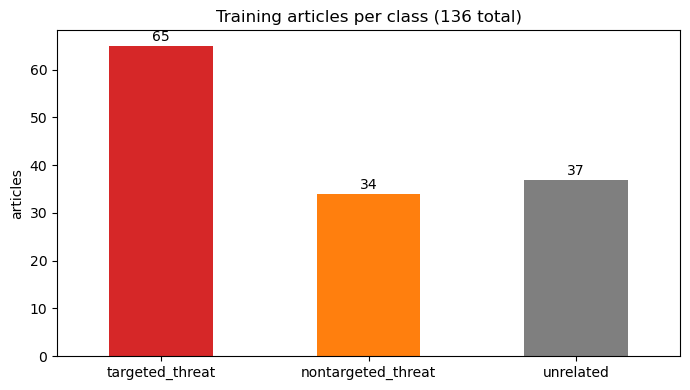

,articles,% of total,median words
label,,,
targeted_threat,65,47.8,229.0
nontargeted_threat,34,25.0,358.0
unrelated,37,27.2,431.0


In [3]:
counts = training["label"].value_counts().reindex(LABELS)

ax = counts.plot(kind="bar", figsize=(7, 4), color=["tab:red", "tab:orange", "tab:gray"])
ax.set_ylabel("articles")
ax.set_xlabel("")
ax.set_title("Training articles per class (136 total)")
for i, n in enumerate(counts):
    ax.text(i, n + 1, str(n), ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "baseline_class_counts.png"), dpi=200)
plt.show()

summary = pd.DataFrame({
    "articles": counts,
    "% of total": (counts / len(training) * 100).round(1),
    "median words": training.groupby("label")["words"].median().reindex(LABELS),
})
summary

In [4]:
pd.crosstab(training["label"], training["agreement"], margins=True, margins_name="total").reindex(LABELS + ["total"])

agreement,adjudicated,all three agreed,two of three,total
label,,,,
targeted_threat,19,33,13,65
nontargeted_threat,13,12,9,34
unrelated,9,27,1,37
total,41,72,23,136


**What we see**

- `targeted_threat` is about half of the data (65 of 136). The other two classes are close to each other (34 and 37). No class is so small that the model could ignore it, so we keep three classes.
- `targeted_threat` articles are shorter (median of about 230 words). They are usually short local news about one school.
- 72 articles had all three annotators agreeing. The other 64 needed a majority or the rules. This is the data we have, so we read the results with that in mind.

## Block 3: The keyword search we have to beat

**This block handles the comparison point.** These are three plain rules, the kind of thing someone would try first without a model:

1. If the text has no threat word (`threat`, `bomb`, `shooting`, `gun`, `weapon`), the article is `unrelated`.
2. If it has a threat word and names a school ("Something High School", "Middle School", "Elementary School"), it is `targeted_threat`.
3. If it has a threat word but names no school, it is `nontargeted_threat`.

To compare the keyword search and the model the same way, both are scored with one function.

In [5]:
THREAT_WORDS = ["threat", "bomb", "shooting", "gun", "weapon"]

# A capitalized name followed by a school type, for example "Oxford High School".
SCHOOL_NAME = r"[A-Z][a-z]+ (High|Middle|Elementary) School"


def keyword_label(text):
    if not any(word in text.lower() for word in THREAT_WORDS):
        return "unrelated"
    if re.search(SCHOOL_NAME, text):
        return "targeted_threat"
    return "nontargeted_threat"


def score(predicted):
    """Accuracy, kappa and per-class recall against our final labels."""
    recall = recall_score(training["label"], predicted, labels=LABELS, average=None)
    result = {
        "accuracy": accuracy_score(training["label"], predicted),
        "kappa": cohen_kappa_score(training["label"], predicted),
    }
    for label, value in zip(LABELS, recall):
        result["recall " + label] = value
    return pd.Series(result).round(3)


training["keyword"] = training["text"].apply(keyword_label)

print(score(training["keyword"]).to_string())
pd.crosstab(training["label"], training["keyword"], rownames=["our label"], colnames=["keyword search"])

accuracy                     0.662
kappa                        0.448
recall targeted_threat       0.877
recall nontargeted_threat    0.647
recall unrelated             0.297


keyword search,nontargeted_threat,targeted_threat,unrelated
our label,,,
nontargeted_threat,22,12,0
targeted_threat,8,57,0
unrelated,14,12,11


**What we see**

- The keyword search is already decent: a kappa of about 0.45, which is moderate.
- It finds almost every `targeted_threat` (recall near 0.9), because those articles nearly always name a school.
- It fails on `unrelated`: it finds only about 3 in 10. Most `unrelated` articles still say "threat", "gun" or "shooting" (a lockdown for another reason, the Oxford shooting, a rumor), so a word search cannot tell them apart. This is the same problem people had in round 2.

## Block 4: The first model

**This block handles the model.** TF-IDF turns each article into a list of word weights: a word gets more weight when it is common in that article and rare in the others. Logistic regression then learns which words point to each class.

We used simple, common settings. Other common settings (word pairs, a different regularization strength, keeping one-off words) gave a kappa between 0.64 and 0.73 on the same split, so the result does not depend on this choice. The settings are:

- English stop words (`the`, `and`...) are removed.
- A word has to appear in at least 2 articles, so one-off names do not count.
- `class_weight="balanced"` makes the smaller classes count as much as `targeted_threat`.

**How we test it.** With only 136 articles we cannot spare a large test set, so we use 5-fold cross-validation. The articles are split into 5 groups with the same class mix. The model trains on 4 groups and predicts the 5th, five times, so every article is predicted by a model that never saw it.

In [6]:
model = make_pipeline(
    TfidfVectorizer(stop_words="english", min_df=2),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
training["model"] = cross_val_predict(model, training["text"], training["label"], cv=folds)

print(score(training["model"]).to_string())
pd.crosstab(training["label"], training["model"], rownames=["our label"], colnames=["model"])

accuracy                     0.831
kappa                        0.733
recall targeted_threat       0.846
recall nontargeted_threat    0.853
recall unrelated             0.784


model,nontargeted_threat,targeted_threat,unrelated
our label,,,
nontargeted_threat,29,3,2
targeted_threat,6,55,4
unrelated,0,8,29


With so few articles, the result can depend on which articles land in which fold. To check, we repeat the cross-validation with 10 different random splits.

In [7]:
kappas = []
for seed in range(10):
    folds_seed = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    predicted = cross_val_predict(model, training["text"], training["label"], cv=folds_seed)
    kappas.append(cohen_kappa_score(training["label"], predicted))

print("Kappa over 10 random splits")
print("lowest:", round(min(kappas), 3))
print("average:", round(np.mean(kappas), 3))
print("highest:", round(max(kappas), 3))

Kappa over 10 random splits
lowest: 0.601
average: 0.676
highest: 0.707


**What we see**

- The model is right on about 8 of every 10 articles, with a kappa of about 0.73 on the main split.
- Over 10 different splits the kappa stays between about 0.60 and 0.71 (average about 0.68). The main split was on the lucky side, so **about 0.68 is the honest number to report**.
- The big gain is on `unrelated`: the model finds about 8 in 10, against 3 in 10 for the keyword search.
- Its most common mistakes are calling an `unrelated` article `targeted_threat` (8 articles) and a `targeted_threat` article `nontargeted_threat` (6 articles).

## Block 5: Is the model worth it?

**This block handles the decision.** We check the model against the three criteria we set at the start.

In [8]:
keyword_scores = score(training["keyword"])
model_scores = score(training["model"])
recall_columns = ["recall " + label for label in LABELS]

criteria = pd.DataFrame({
    "criterion": [
        "Beats the keyword search on kappa",
        "Kappa of at least 0.40",
        "Recall of at least 0.50 for every class",
    ],
    "keyword search": [
        round(keyword_scores["kappa"], 2),
        round(keyword_scores["kappa"], 2),
        round(keyword_scores[recall_columns].min(), 2),
    ],
    "model": [
        round(model_scores["kappa"], 2),
        round(model_scores["kappa"], 2),
        round(model_scores[recall_columns].min(), 2),
    ],
    "passes": [
        model_scores["kappa"] > keyword_scores["kappa"],
        model_scores["kappa"] >= 0.40,
        model_scores[recall_columns].min() >= 0.50,
    ],
})
criteria

,criterion,keyword search,model,passes
0,Beats the keyword search on kappa,0.45,0.73,True
1,Kappa of at least 0.40,0.45,0.73,True
2,Recall of at least 0.50 for every class,0.30,0.78,True


**What we see**

- The model passes all three criteria, so it is worth keeping and improving.
- The keyword search would fail the third one, because it misses most `unrelated` articles.
- Even the worst of the 10 splits (kappa of about 0.60) would still pass the first two criteria.

## Block 6: Is the model wrong on the same articles as people?

**This block handles one question:** if an article was hard for us to agree on, is it also hard for the model? We compare how often each method is right, split by how much the annotators agreed.

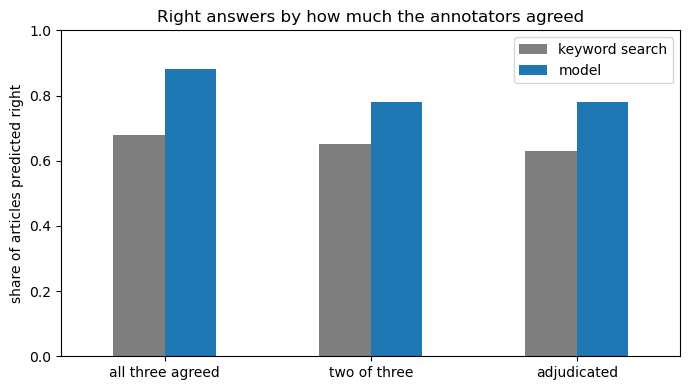

,articles,keyword_right,model_right
agreement,,,
all three agreed,72,0.68,0.88
two of three,23,0.65,0.78
adjudicated,41,0.63,0.78


In [9]:
training["keyword_right"] = training["keyword"] == training["label"]
training["model_right"] = training["model"] == training["label"]

by_agreement = training.groupby("agreement").agg(
    articles=("label", "size"),
    keyword_right=("keyword_right", "mean"),
    model_right=("model_right", "mean"),
)
by_agreement = by_agreement.reindex(["all three agreed", "two of three", "adjudicated"]).round(2)

ax = by_agreement[["keyword_right", "model_right"]].plot(kind="bar", figsize=(7, 4), color=["tab:gray", "tab:blue"])
ax.set_ylabel("share of articles predicted right")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.set_title("Right answers by how much the annotators agreed")
ax.legend(["keyword search", "model"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "baseline_by_agreement.png"), dpi=200)
plt.show()

by_agreement

**What we see**

- When all three annotators agreed, the model is right on almost 9 of every 10 articles.
- When people disagreed (two of three, or adjudicated), the model drops to about 8 in 10.
- So the articles that were hard for us are also harder for the model. This supports the idea that part of the difficulty is in the task itself, not only in the people.
- The model beats the keyword search at every level.

## Block 7: Which words the model leans on

**This block handles a first look at Question 2.** The model is trained once on all 136 articles, and for each class we list the 10 words that push an article most toward it. This is a quick preview; the proper answer to Question 2 will use SHAP later.

In [10]:
model.fit(training["text"], training["label"])

words = model.named_steps["tfidfvectorizer"].get_feature_names_out()
weights = model.named_steps["logisticregression"].coef_
classes = model.named_steps["logisticregression"].classes_

top_words = pd.DataFrame({
    label: words[np.argsort(weights[i])[::-1][:10]]
    for i, label in enumerate(classes)
})
top_words[LABELS]

,targeted_threat,nontargeted_threat,unrelated
0,school,tiktok,lockdown
1,middle,threats,covid
2,threat,schools,2026
3,police,social,19
4,student,media,rumor
5,high,districts,updated
6,threatening,challenge,williams
7,says,district,oxford
8,teen,enforcement,fbi
9,st,credible,coronavirus


**What we see**

- `nontargeted_threat` leans on the trend itself: `tiktok`, `social`, `media`, `districts`, `challenge`, `credible`. That matches the codebook: coverage of the viral trend, with no single school.
- `targeted_threat` leans on one school and one event: `middle`, `high`, `police`, `student`, `threatening`, `teen`.
- `unrelated` leans on other topics: `lockdown`, `covid`, `rumor`, `oxford`, `fbi`. That matches the rules for lockdowns for another reason, rumors and the Oxford shooting.
- Some words look like page leftovers rather than news (`updated`, `2026`), and `williams` is just a name. They probably come from dates and bylines on the web page. #TODO later: check whether cleaning them changes the results.

## Conclusions

| | Keyword search | Model (main split) | Model (10 splits) |
|---|---|---|---|
| Accuracy | about 0.66 | about 0.83 | |
| Cohen kappa | about 0.45 | about 0.73 | 0.60 to 0.71, average 0.68 |
| Lowest recall per class | 0.30 (`unrelated`) | about 0.78 | |
| Passes the 3 criteria | No | Yes | |

**Answer so far to Question 1: yes.** A simple model separates the three classes clearly better than a keyword search, with moderate to substantial agreement with our labels (kappa of about 0.68). The real gain is on `unrelated`, the class people also found hardest.

**Decisions we took in this notebook**

1. Trained on the 136 labeled articles that have text, and dropped 2 without text.
2. Kept three classes, because none is too small.
3. Reported the average of 10 random splits (0.68) instead of the best one (0.73), and checked that other common settings give similar results.

**Limitations**

- 136 articles is small, so the numbers move a few points from one split to another.
- All the training articles are from the 2021 TikTok trend. We do not know yet how the model does on 2016 or 2026.
- Almost half of the labels needed a majority vote or the rules, so the labels themselves carry some noise.

**Next steps (#TODO later)**

- #TODO: Use SHAP for Question 2, instead of only the word weights.
- #TODO: Remove page leftovers (dates, "updated") from the text and re-run.
- #TODO: Try at least one other model (for example, linear SVM or naive Bayes) with the same 5 folds.
- #TODO: Label a small set from 2016 or 2026 to check whether the model works outside 2021.
- #TODO: Rename the files and figures once the final structure is decided.